# Example of the aitlas toolbox in the context of change detection

The xView2 dataset contains label files in GeoJSON format.

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import xView2Dataset
from aitlas.utils import image_loader
from aitlas.models import UnetChangeDetection
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Multilabel classification

Total number of patches: 2799


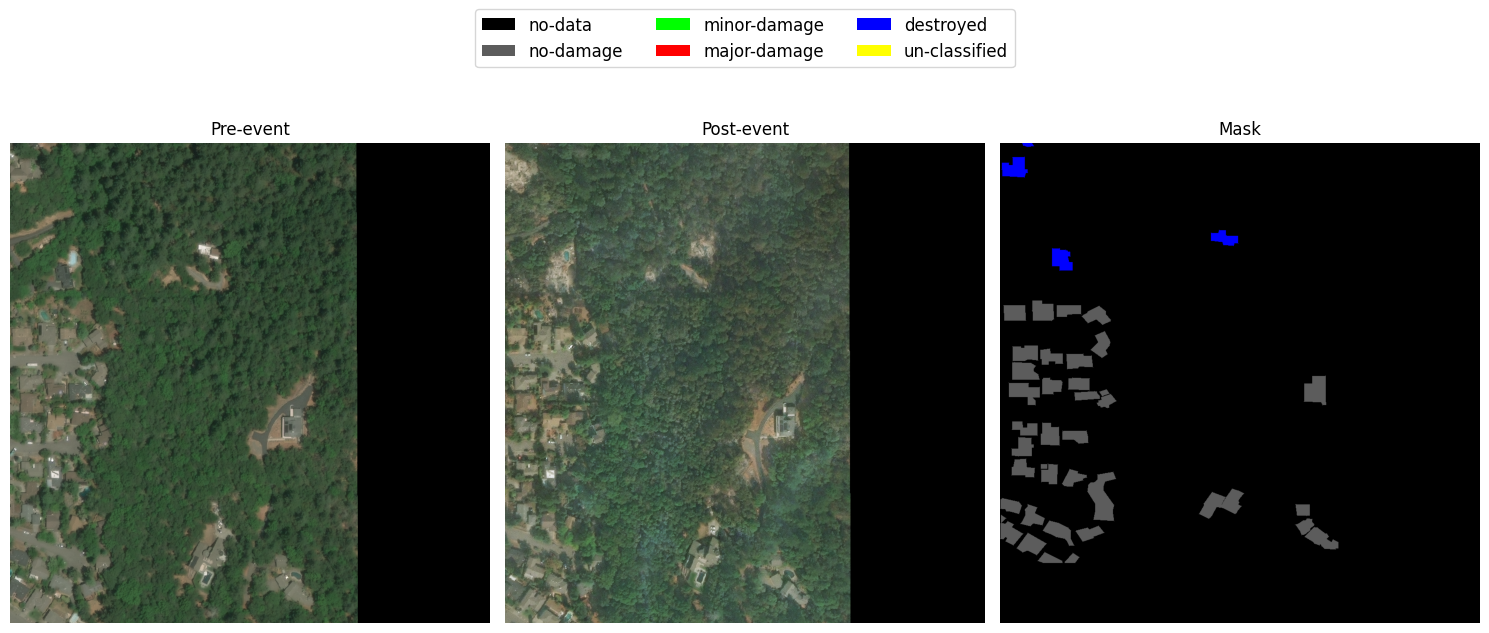

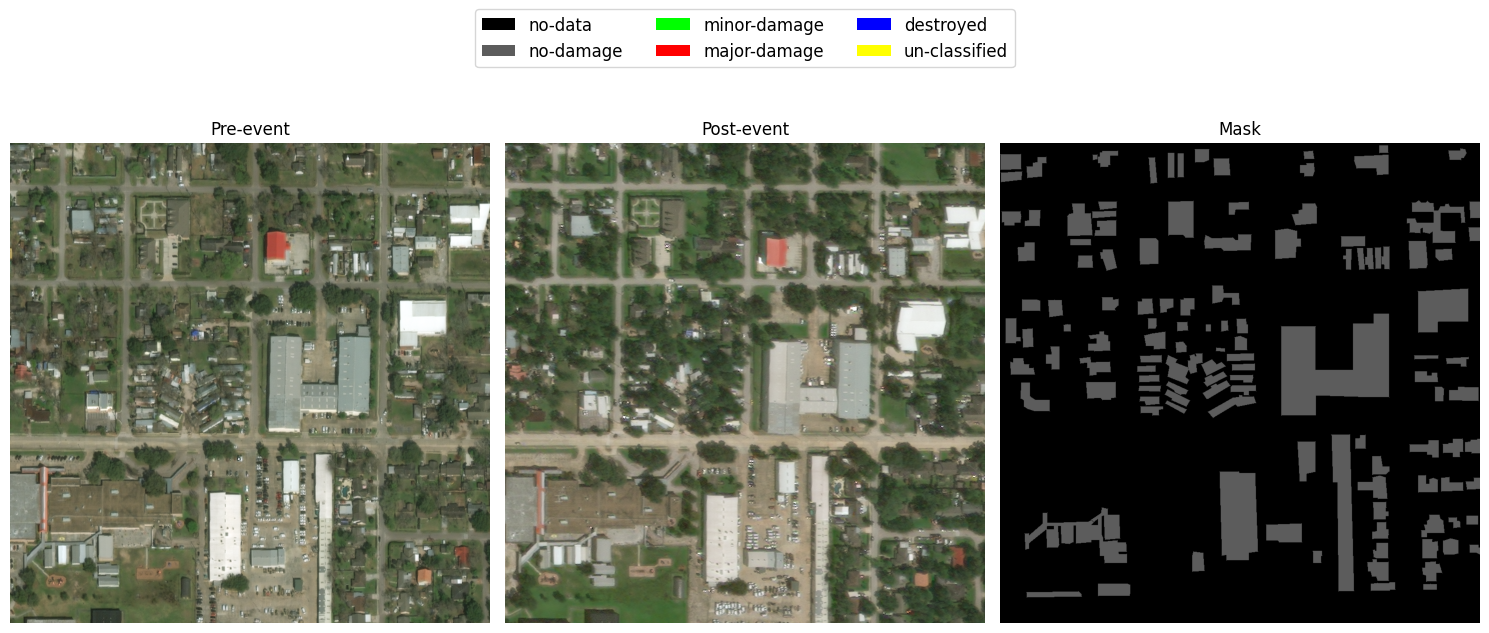

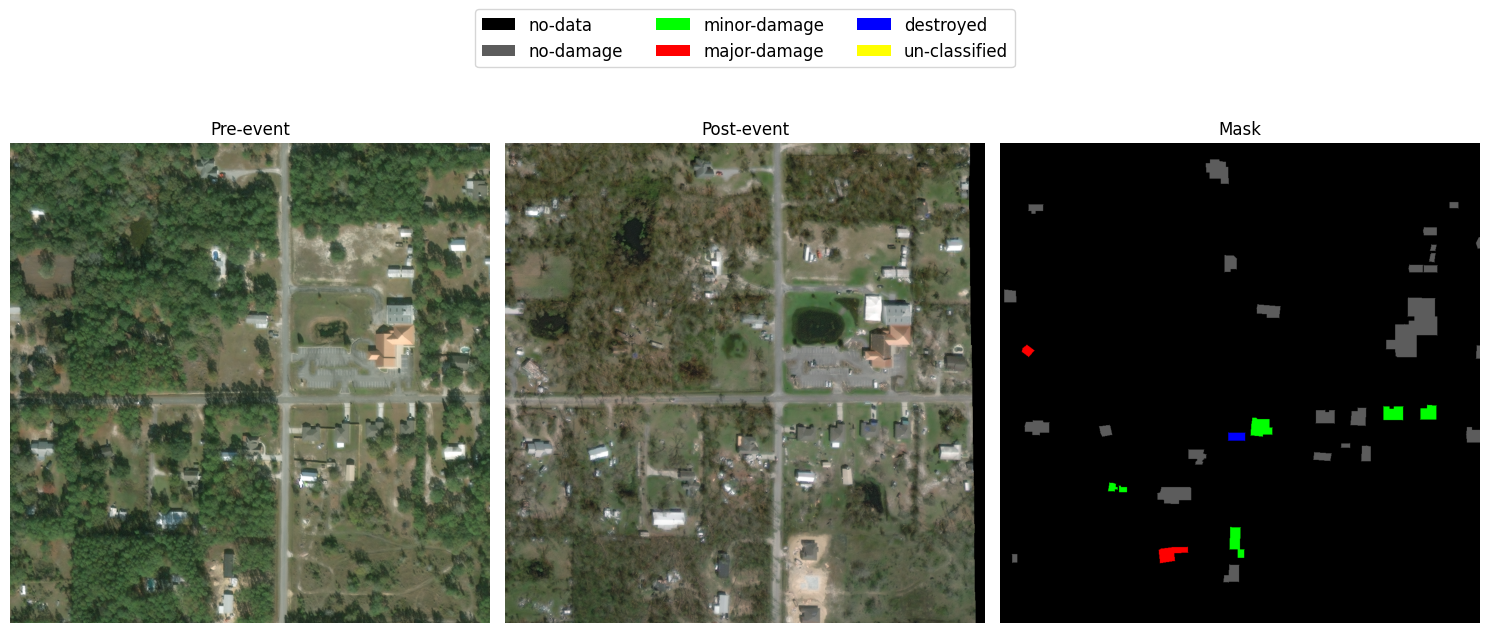

In [ ]:
dataset_config = {
    "data_dir" : "./data/xview2/geotiffs/tier1/",
    "classification": "multilabel"
}
dataset = xView2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(1000);
dataset.show_image(2200);

Binary classification

Total number of patches: 2799


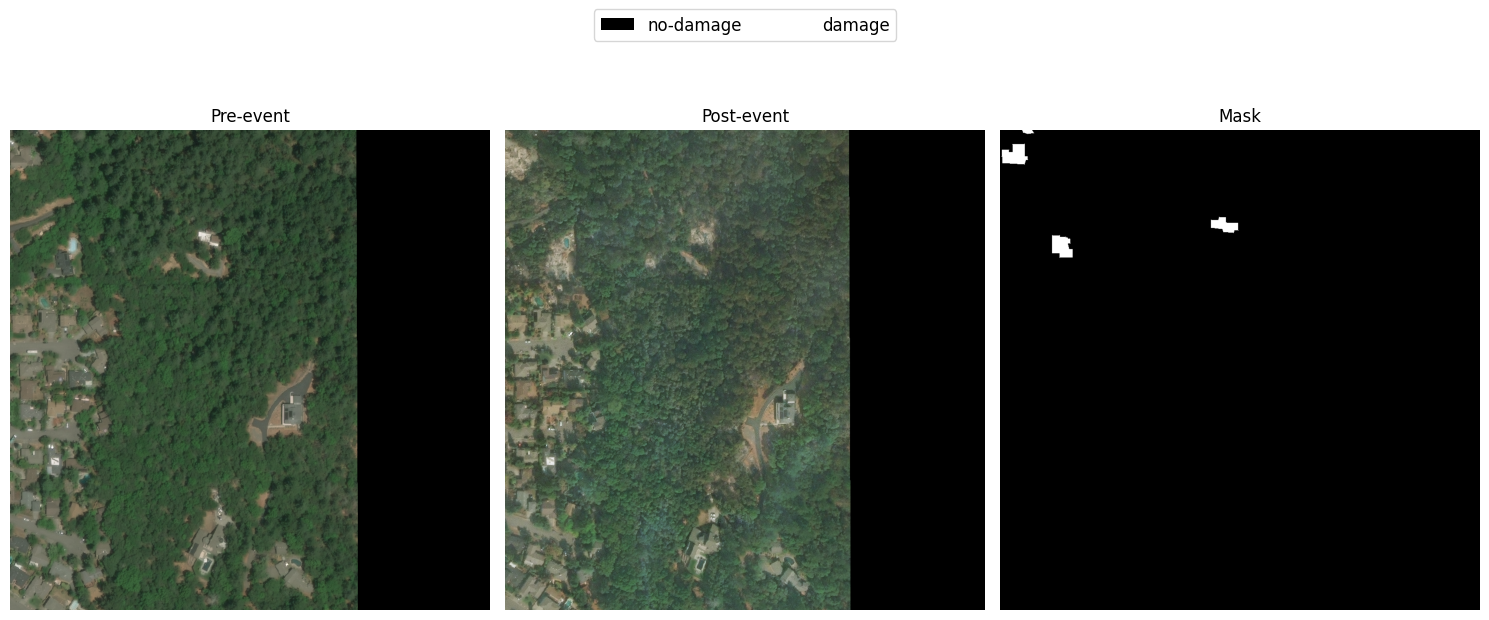

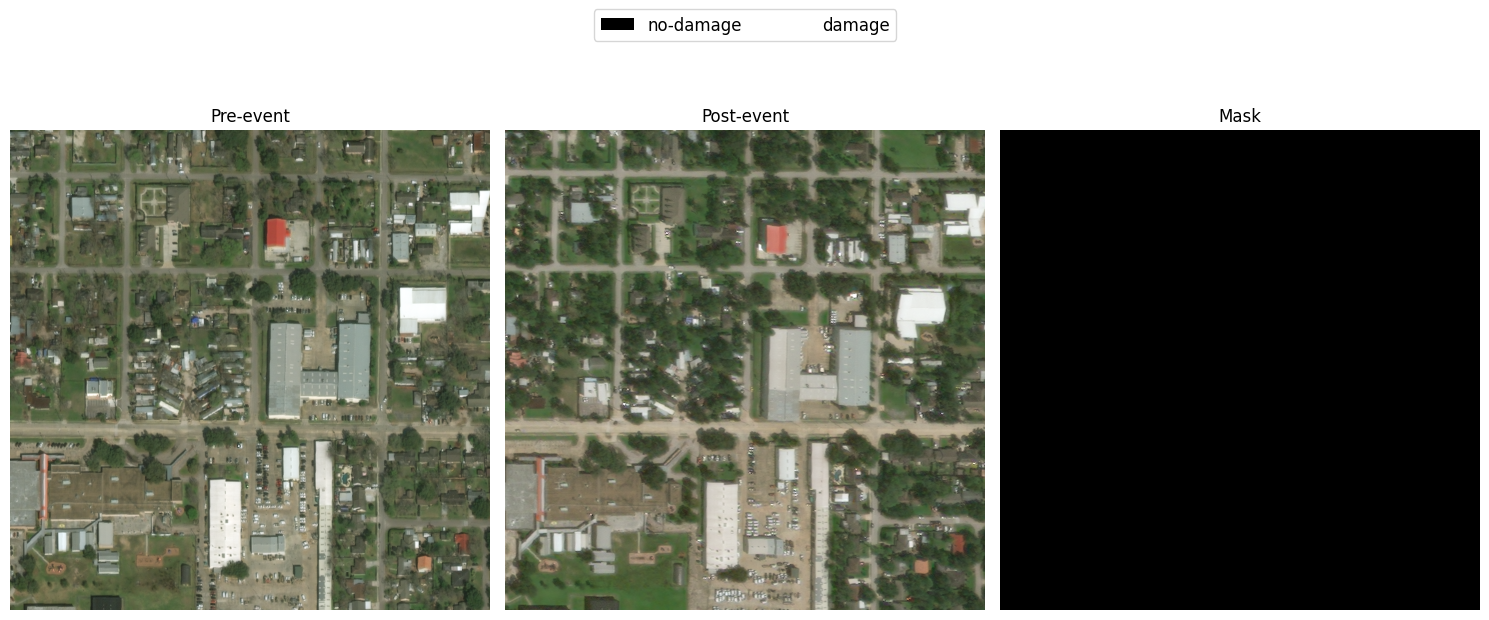

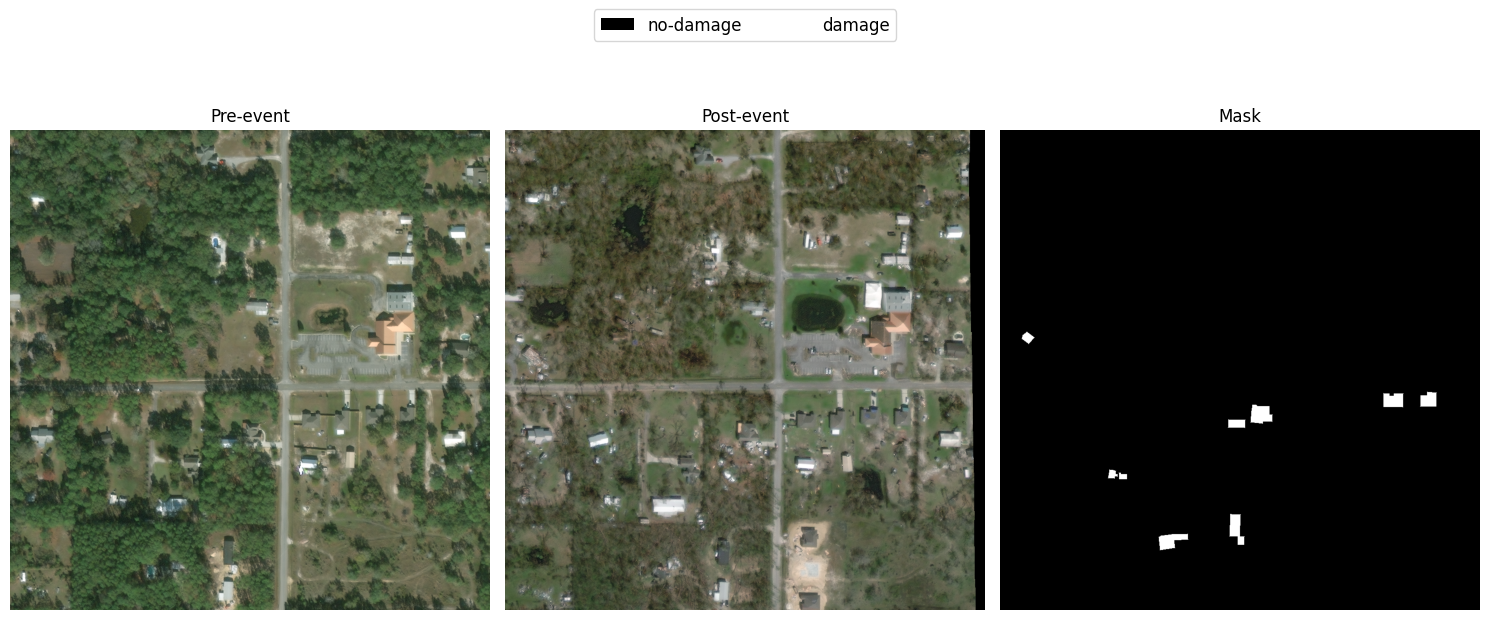

In [ ]:
dataset_config = {
    "data_dir" : "./data/xview2/geotiffs/tier1/",
    "classification": "binary"
}
dataset = xView2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

dataset.show_image(10);
dataset.show_image(1000);
dataset.show_image(2200);

In [ ]:
dataset_config = {
    "data_dir" : "./data/xview2/geotiffs/tier1/",
    "classification": "multilabel"
}
dataset = xView2Dataset(dataset_config)

dataset.data_distribution_table()

,Number of pixels
no-data,2.777520e+09
no-damage,1.155723e+08
minor-damage,1.425477e+07
major-damage,1.787003e+07
destroyed,8.382925e+06
un-classified,1.364406e+06


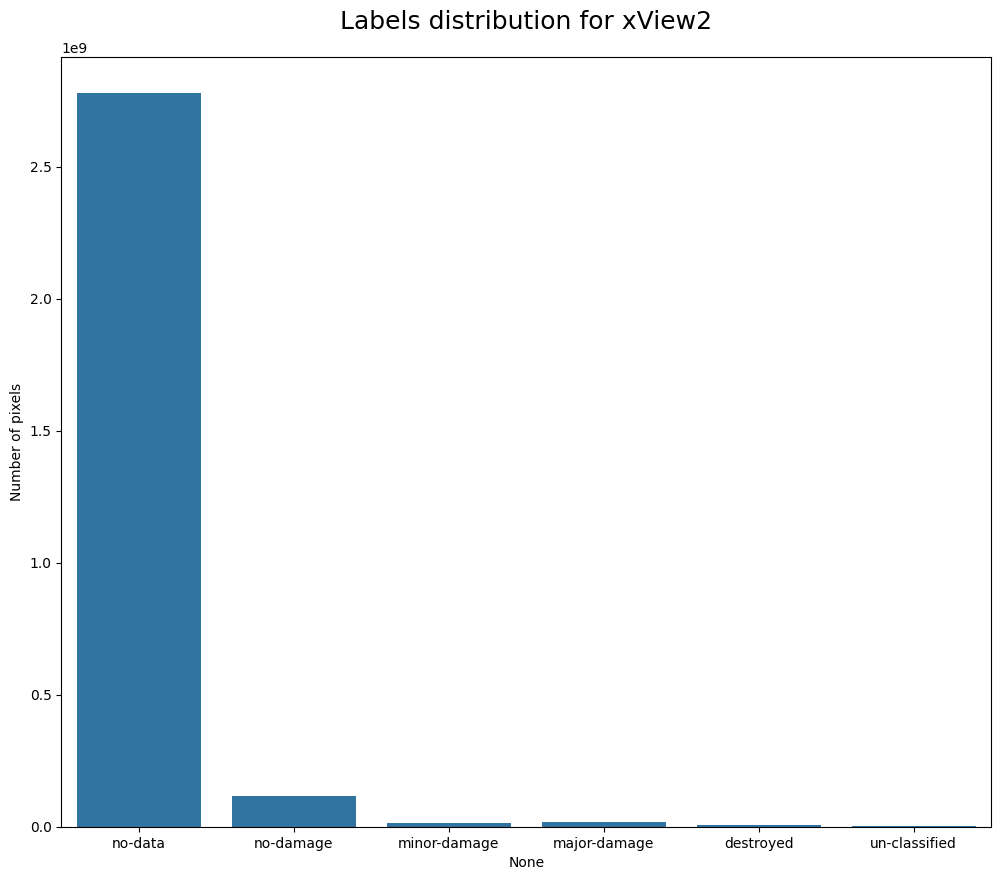

In [72]:
dataset.data_distribution_barchart();

## Load training and test data

In [ ]:

train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/xview2/geotiffs/tier1/",
    "classification": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = xView2Dataset(train_dataset_config)

test_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/xview2/geotiffs/tier3/",
    "classification": "binary",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
test_dataset = xView2Dataset(test_dataset_config)
len(train_dataset), len(test_dataset)

(2799, 6369)

## Create the model

In [ ]:
epochs = 5
model_directory = "./data/experiments/xview2"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": False, 
    "threshold": 0.5,
    "metrics": ["accuracy", "precision", "recall", "f1_score", "iou"]
}

model = UnetChangeDetection(model_config)
model.prepare()

## Start the training

In [9]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1',
)

model_path = model_directory + "/checkpoint.pth.tar"
model.load_model(model_path)
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
test_metrics = model.running_metrics.get_scores(model.metrics)

2026-04-30 08:36:51,207 INFO Starting training.
training: 100%|██████████| 350/350 [01:08<00:00,  5.13it/s]
2026-04-30 08:37:59,475 INFO epoch: 1, loss:  0.16288
testing on train set: 100%|██████████| 350/350 [01:06<00:00,  5.23it/s]
2026-04-30 08:39:07,881 INFO Accuracy:0.9850094554338255, Accuracy per Class:[0.97848584 0.99153307], Precision Micro:0.9799198880914036, Precision Macro:0.5511276882183969, Precision Weighted:0.9729264566756027, Precision per Class:[0.9801229  0.12213247], Recall Micro:0.9899458408788796, Recall Macro:0.5008852775269639, Recall Weighted:0.9899458408788795, Recall per Class:[0.99828986 0.00348069], F1_score Micro:0.9849073501244873, F1_score Macro:0.4979457292912822, F1_score Weighted:0.9808834154602621, F1_score per Class:[0.98912297 0.00676848], IOU:0.970263502789892, IOU mean:0.49093787836893144, IOU per Class:[0.97848002 0.00339573]
training: 100%|██████████| 350/350 [01:14<00:00,  4.72it/s]
2026-04-30 08:40:22,061 INFO epoch: 2, loss:  0.05413
testing

## Predictions

2026-04-30 08:54:59,525 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/xview2/checkpoint.pth.tar
2026-04-30 08:54:59,902 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/xview2/checkpoint.pth.tar at epoch 6


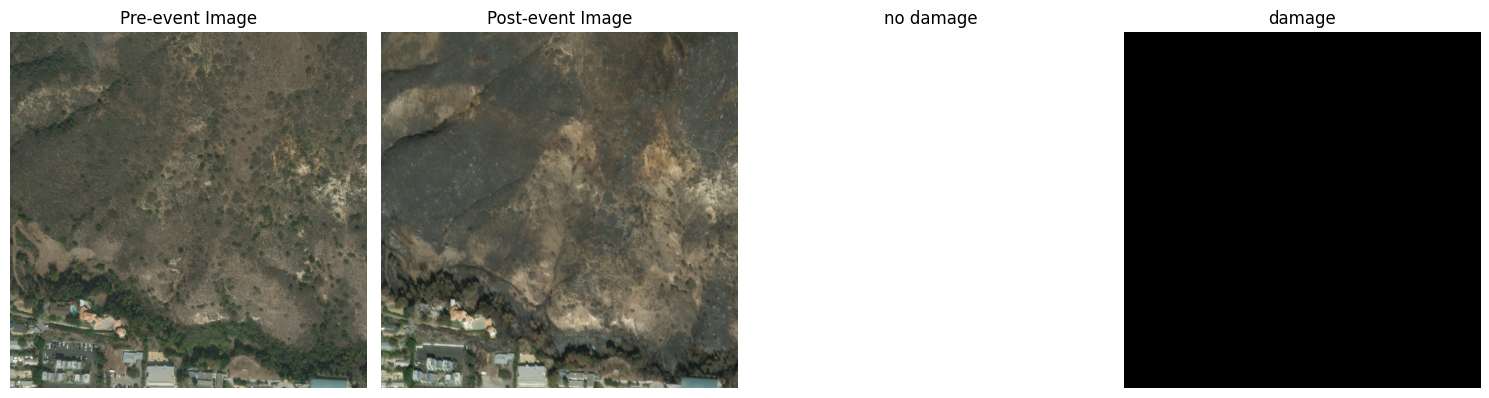

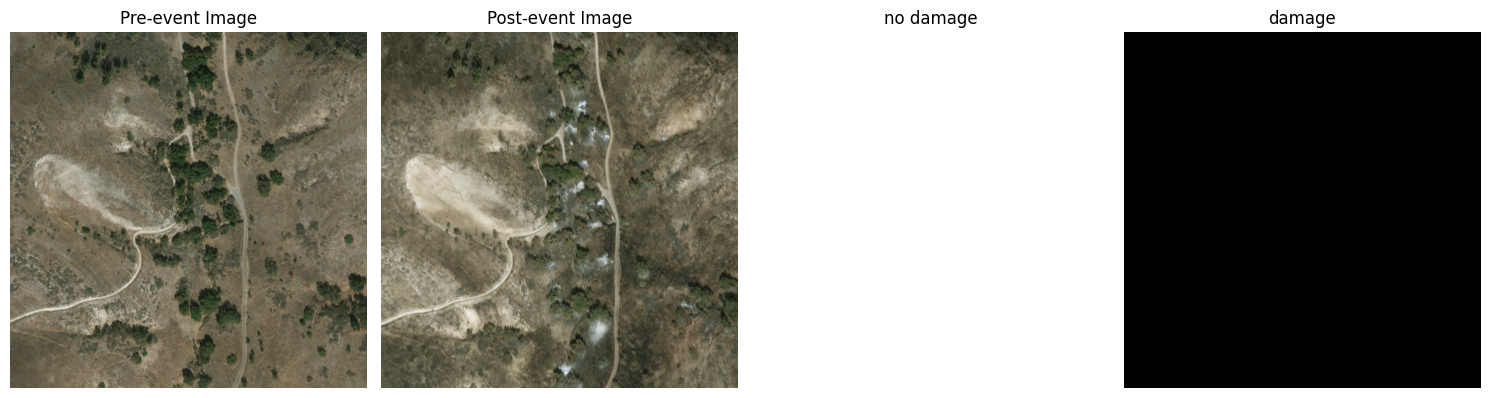

In [ ]:
model_path = "./data/experiments/xview2/checkpoint.pth.tar"
labels = ["no damage","damage"]
transform = ResizeToTensor()
model.load_model(model_path)

image1 = image_loader("./data/xview2/geotiffs/test/images/socal-fire_00001400_pre_disaster.tif").astype(np.uint8)
image2 = image_loader("./data/xview2/geotiffs/test/images/socal-fire_00001400_post_disaster.tif").astype(np.uint8)
fig = model.predict_masks(image1, image2, labels, transform)

image1 = image_loader("./data/xview2/geotiffs/test/images/socal-fire_00001326_pre_disaster.tif").astype(np.uint8)
image2 = image_loader("./data/xview2/geotiffs/test/images/socal-fire_00001326_post_disaster.tif").astype(np.uint8)
fig = model.predict_masks(image1, image2, labels, transform)